## Lesson 23 – Baselines: the bar every model must beat

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIG = "../figures/"
df = pd.read_csv("../data/processed/dataset_daily.csv", index_col="date", parse_dates=True)
df = df.asfreq("D")
y = df["consumption_gwh"]

val = y["2023"]
test = y["2024":"2025"]
print(len(y[:"2022"]), len(val), len(test))     # expect 5113 365 731

5113 365 731


In [7]:
def evaluate(actual, pred, name):
    """MAE, RMSE (GWh) and MAPE (%) of a forecast, as one row."""
    err = actual - pred
    return pd.Series({"MAE": np.mean(np.abs(err)),
                      "RMSE": np.sqrt(np.mean(err**2)),
                      "MAPE (%)": np.mean(np.abs(err / actual)) * 100}, name=name)

SCORES = Path("../results/scores.csv")
SCORES.parent.mkdir(exist_ok=True)

def log_scores(table, period):
    """Append a scores table to results/scores.csv (replacing older rows of the same model + period)."""
    new = table.reset_index(names="model").assign(period=period)
    if SCORES.exists():
        old = pd.read_csv(SCORES)
        old = old[~(old["model"].isin(new["model"]) & (old["period"] == period))]
        new = pd.concat([old, new], ignore_index=True)
    new.round(3).to_csv(SCORES, index=False)

In [3]:
baselines = {
    "naive (yesterday)":           y.shift(1),
    "seasonal naive (last week)":  y.shift(7),
    "yearly naive (52 weeks ago)": y.shift(364),
}
val_scores = pd.DataFrame([evaluate(val, f[val.index], name) for name, f in baselines.items()])
log_scores(val_scores, "validation 2023")
val_scores.round(2)

,MAE,RMSE,MAPE (%)
naive (yesterday),9.30,12.98,6.60
seasonal naive (last week),7.98,10.74,5.37
yearly naive (52 weeks ago),8.97,11.38,6.26


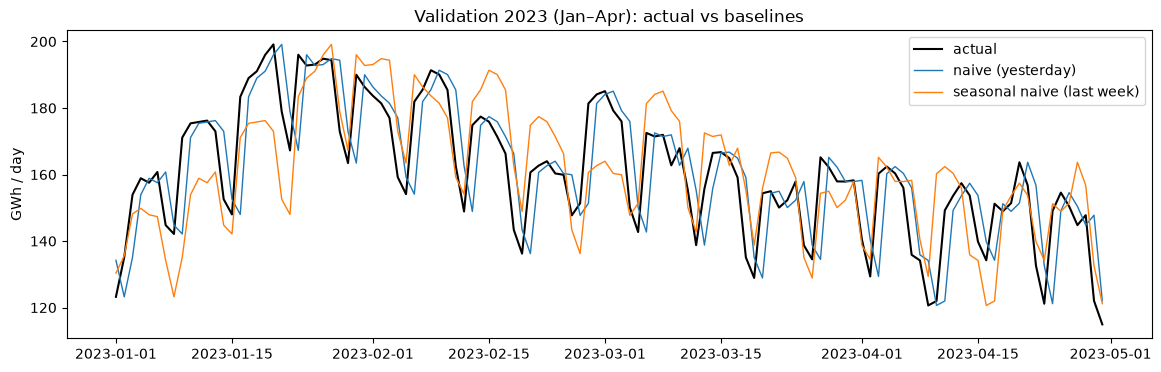

In [4]:
period = slice("2023-01-01", "2023-04-30")
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(val[period], color="black", lw=1.5, label="actual")
ax.plot(baselines["naive (yesterday)"][period], lw=1, label="naive (yesterday)")
ax.plot(baselines["seasonal naive (last week)"][period], lw=1, label="seasonal naive (last week)")
ax.set_ylabel("GWh / day"); ax.legend(loc="upper right")
ax.set_title("Validation 2023 (Jan–Apr): actual vs baselines")
fig.savefig(FIG + "baselines_val_zoom.png", dpi=150, bbox_inches="tight")

## Lesson 24 – Holt-Winters (exponential smoothing)

In [5]:
import warnings
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def hw_day_ahead(y_fit, y_run, trend, damped):
    """Estimate parameters on y_fit, then return one-step-ahead forecasts over y_run with those parameters fixed."""
    spec = dict(trend=trend, damped_trend=damped, seasonal="add",
                seasonal_periods=7, initialization_method="heuristic")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        est = ExponentialSmoothing(y_fit, **spec).fit()
        keys = ["smoothing_level", "smoothing_trend", "smoothing_seasonal", "damping_trend"]
        fixed = {k: est.params[k] for k in keys
                 if est.params.get(k) is not None and not np.isnan(est.params[k])}
        run = ExponentialSmoothing(y_run, **spec).fit(**fixed, optimized=False)
    return run.fittedvalues, fixed

variants = {
    "Holt-Winters (no trend)":     (None, False),
    "Holt-Winters (trend)":        ("add", False),
    "Holt-Winters (damped trend)": ("add", True),
}
hw_preds, hw_params = {}, {}
for name, (trend, damped) in variants.items():
    hw_preds[name], hw_params[name] = hw_day_ahead(y[:"2022"], y[:"2023"], trend, damped)

hw_scores = pd.DataFrame([evaluate(val, p[val.index], n) for n, p in hw_preds.items()])
log_scores(hw_scores, "validation 2023")
display(pd.concat([val_scores.loc[["seasonal naive (last week)"]], hw_scores]).round(2))
pd.DataFrame(hw_params).T.round(3)

,MAE,RMSE,MAPE (%)
seasonal naive (last week),7.98,10.74,5.37
Holt-Winters (no trend),3.58,5.28,2.50
Holt-Winters (trend),3.59,5.28,2.50
Holt-Winters (damped trend),3.58,5.28,2.50


,smoothing_level,smoothing_seasonal,smoothing_trend,damping_trend
Holt-Winters (no trend),0.792,0.011,NaN,NaN
Holt-Winters (trend),0.798,0.010,0.004,NaN
Holt-Winters (damped trend),0.791,0.011,0.000,0.916


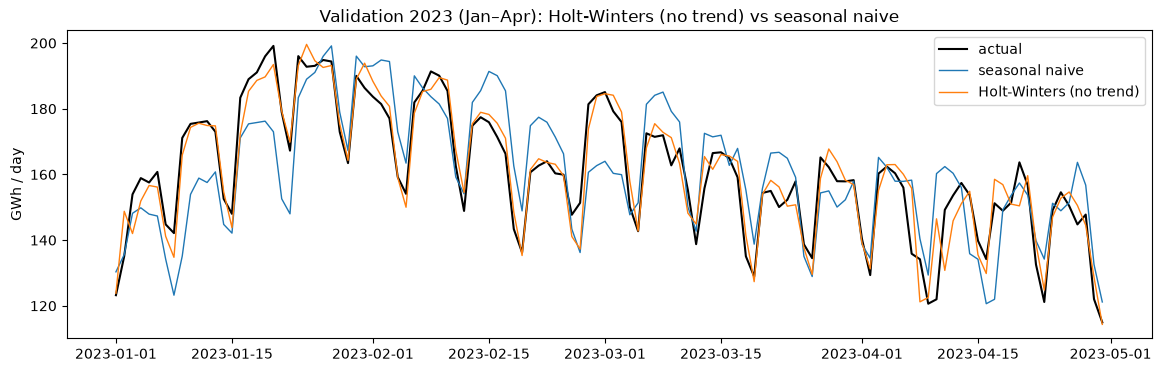

In [6]:
best_hw = hw_scores["MAE"].idxmin()
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(val[period], color="black", lw=1.5, label="actual")
ax.plot(baselines["seasonal naive (last week)"][period], lw=1, label="seasonal naive")
ax.plot(hw_preds[best_hw][period], lw=1, label=best_hw)
ax.set_ylabel("GWh / day"); ax.legend(loc="upper right")
ax.set_title(f"Validation 2023 (Jan–Apr): {best_hw} vs seasonal naive")
fig.savefig(FIG + "holtwinters_val_zoom.png", dpi=150, bbox_inches="tight")

## Lesson 25 – What's left in the errors, and the final test

,lb_stat,lb_pvalue
7,26.2765,0.0004
14,28.0770,0.0139


,error (GWh),weekday,is_holiday,temp (°C)
date,,,,
2023-12-25,-30.8,Monday,True,7.1
2023-04-10,-24.5,Monday,True,10.8
2023-05-18,-24.2,Thursday,True,11.9
2023-05-29,-20.6,Monday,True,18.4
2023-04-07,-19.9,Friday,True,6.7
2023-04-11,18.4,Tuesday,False,11.0
2023-05-30,16.0,Tuesday,False,18.5
2023-02-26,14.1,Sunday,False,1.4
2023-01-02,-13.6,Monday,False,9.6


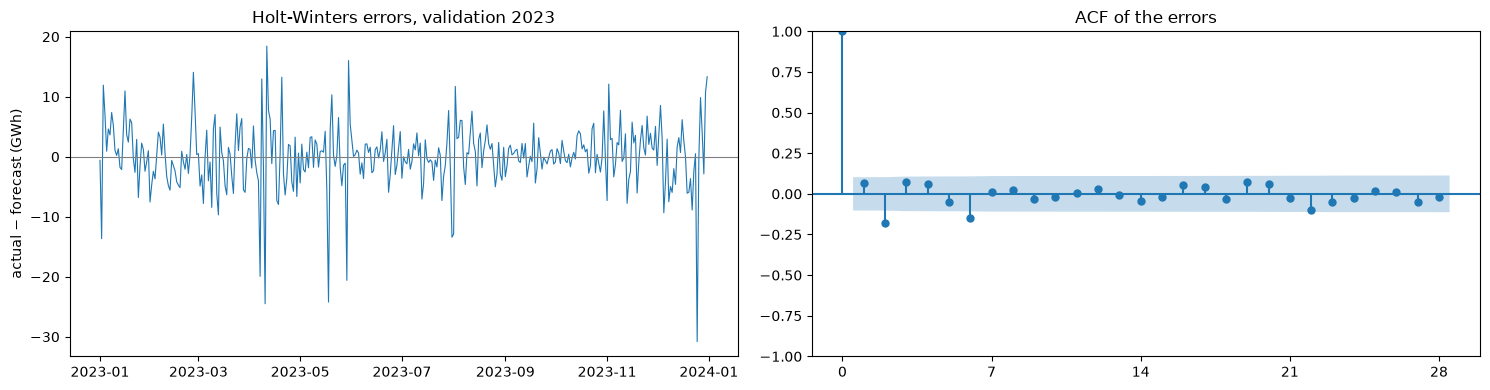

In [8]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

best = "Holt-Winters (no trend)"
resid = val - hw_preds[best][val.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(resid, lw=0.8); axes[0].axhline(0, color="gray", lw=0.8)
axes[0].set_title("Holt-Winters errors, validation 2023"); axes[0].set_ylabel("actual − forecast (GWh)")
plot_acf(resid, lags=28, ax=axes[1]); axes[1].set_xticks(range(0, 29, 7))
axes[1].set_title("ACF of the errors")
fig.tight_layout(); fig.savefig(FIG + "holtwinters_residuals.png", dpi=150, bbox_inches="tight")

display(acorr_ljungbox(resid, lags=[7, 14], return_df=True).round(4))

top = resid.abs().nlargest(10).index
pd.DataFrame({"error (GWh)": resid[top].round(1), "weekday": top.day_name(),
              "is_holiday": df.loc[top, "is_holiday"], "temp (°C)": df.loc[top, "temp_ch"].round(1)})

In [9]:
# baselines need no fitting: same shifts, scored on the test days
test_scores = [evaluate(test, f[test.index], name) for name, f in baselines.items()]

# Holt-Winters: estimate on 2009–2023 (refit), then run day-ahead through 2024–2025
hw_test_pred, hw_test_params = hw_day_ahead(y[:"2023"], y, trend=None, damped=False)
test_scores.append(evaluate(test, hw_test_pred[test.index], best))

test_scores = pd.DataFrame(test_scores)
log_scores(test_scores, "test 2024–2025")
print("parameters refit on 2009–2023:", {k: round(v, 3) for k, v in hw_test_params.items()})
test_scores.round(2)

parameters refit on 2009–2023: {'smoothing_level': np.float64(0.795), 'smoothing_seasonal': np.float64(0.011)}


,MAE,RMSE,MAPE (%)
naive (yesterday),9.59,13.08,6.83
seasonal naive (last week),7.75,10.85,5.24
yearly naive (52 weeks ago),7.56,10.39,5.12
Holt-Winters (no trend),4.05,5.76,2.85


## Summary – Section 4: Baselines and Holt-Winters (day-ahead)

| Model | Validation 2023 MAE | Test 2024–25 MAE | Test MAPE |
|---|---|---|---|
| Naive (yesterday) | 9.30 | 9.59 | 6.83 % |
| Seasonal naive (last week) | 7.98 | 7.75 | 5.24 % |
| Yearly naive (52 weeks ago) | 8.97 | 7.56 | 5.12 % |
| **Holt-Winters (additive, s = 7, no trend)** | **3.58** | **4.05** | **2.85 %** |

- Holt-Winters halves the error of the best baseline. α ≈ 0.79 (level follows recent days), γ ≈ 0.011 (weekly shape almost fixed); trend useless (β ≈ 0) → no-trend variant kept.
- Remaining errors (Ljung-Box p < 0.05): 9 of the 10 largest are calendar days (holidays, the day after them, Christmas period, bridge day), 1 is a cold day.
- → Next: SARIMAX with holidays, Christmas period, bridge days and HDD as exogenous variables.